# EVI1-U2: Cuaderno de modelos de regresión y clasificación (G-09 a G-12)
**Curso:** Análisis de Datos (SIS323) · UNA-Puno · 2026-II  
**Integrantes:** Mamani Zapana Edward, Mamani Panca Roger Golber, Gutierrez Arratia Kevin Diego

## 1. Regresión lineal simple y análisis de residuos (G-09)

Filas: 320 | Correlación área-precio: 0.82
Intersección (β0): S/ 170.6 | Pendiente (β1): S/ 10.18 por m²
Estimación 60 m²: S/ 782 | 85 m²: S/ 1036
Residuos -> media: 0.00 | desv.: S/ 127.0 | MAE: S/ 99.9


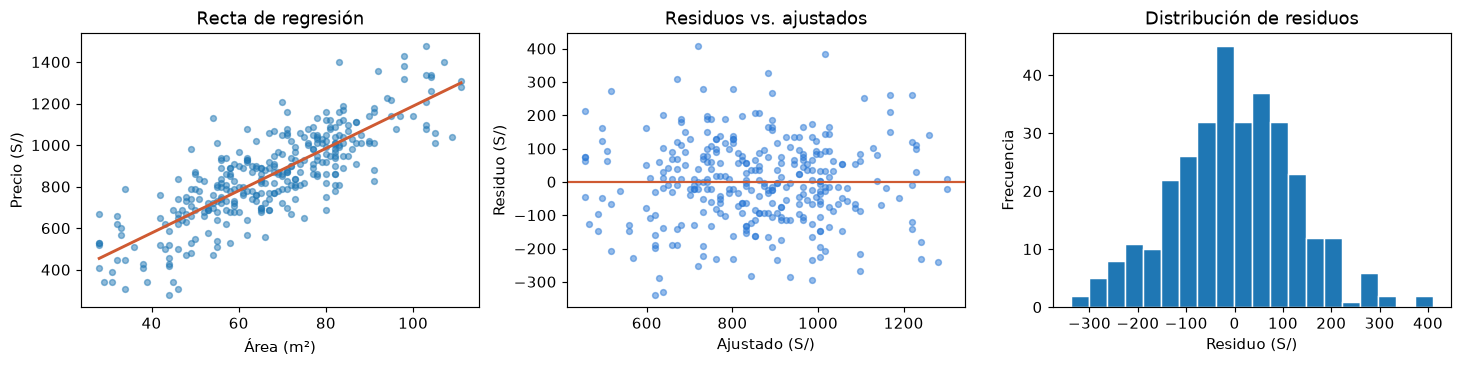

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

BASE_URL = "https://raw.githubusercontent.com/Edwardmamani/Trabajos-UNIDAD-II/main/semana-12"
def cargar_csv(nombre):
    return pd.read_csv(nombre if Path(nombre).exists() else f"{BASE_URL}/{nombre}")

alq = cargar_csv("alquileres_puno_juliaca.csv")
X_s = alq[["area_m2"]]
y_r = alq["precio_soles"]

reg_simple = LinearRegression().fit(X_s, y_r)
ajustado = reg_simple.predict(X_s)
residuos = y_r - ajustado

print(f"Filas: {alq.shape[0]} | Correlación área-precio: {alq['area_m2'].corr(y_r):.2f}")
print(f"Intersección (β0): S/ {reg_simple.intercept_:.1f} | Pendiente (β1): S/ {reg_simple.coef_[0]:.2f} por m²")
print(f"Estimación 60 m²: S/ {reg_simple.predict(pd.DataFrame({'area_m2': [60]}))[0]:.0f} | "
      f"85 m²: S/ {reg_simple.predict(pd.DataFrame({'area_m2': [85]}))[0]:.0f}")
print(f"Residuos -> media: {residuos.mean():.2f} | desv.: S/ {residuos.std():.1f} | MAE: S/ {mean_absolute_error(y_r, ajustado):.1f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
orden = X_s["area_m2"].sort_values()
axes[0].scatter(X_s, y_r, s=16, alpha=0.5)
axes[0].plot(orden, reg_simple.predict(pd.DataFrame({"area_m2": orden})), color="#cf5a32", lw=2)
axes[0].set(title="Recta de regresión", xlabel="Área (m²)", ylabel="Precio (S/)")

axes[1].scatter(ajustado, residuos, s=16, alpha=0.5, color="#2a78d6")
axes[1].axhline(0, color="#cf5a32", lw=1.5)
axes[1].set(title="Residuos vs. ajustados", xlabel="Ajustado (S/)", ylabel="Residuo (S/)")

axes[2].hist(residuos, bins=20, edgecolor="white")
axes[2].set(title="Distribución de residuos", xlabel="Residuo (S/)", ylabel="Frecuencia")
plt.tight_layout()
plt.show()

- **Negocio:** Cada m² adicional incrementa el alquiler en **S/ 10.18**; la intersección (**S/ 170.6**) es solo referencia matemática (no existen departamentos de 0 m²).
- **Residuos:** Centrados en 0, sin curvatura marcada y con distribución aproximadamente simétrica; dispersión típica de ~S/ 100–127 por factores adicionales al área.

## 2. Regresión lineal múltiple y evaluación en prueba (G-10)

In [ ]:
X_r = pd.get_dummies(alq.drop(columns="precio_soles"), drop_first=True, dtype=int)
Xr_ent, Xr_pru, yr_ent, yr_pru = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

def eval_reg(nombre, Xe, Xp):
    m = LinearRegression().fit(Xe, yr_ent)
    pred = m.predict(Xp)
    return {
        "Modelo": nombre,
        "R² prueba": r2_score(yr_pru, pred),
        "RMSE (S/)": np.sqrt(mean_squared_error(yr_pru, pred)),
        "MAE (S/)": mean_absolute_error(yr_pru, pred),
    }, m

res_s, _ = eval_reg("Regresión simple (área)", Xr_ent[["area_m2"]], Xr_pru[["area_m2"]])
res_m, reg_mult = eval_reg("Regresión múltiple (8 var.)", Xr_ent, Xr_pru)

cv_s = cross_val_score(LinearRegression(), X_r[["area_m2"]], y_r, cv=5, scoring="r2")
cv_m = cross_val_score(LinearRegression(), X_r, y_r, cv=5, scoring="r2")
res_s["CV R² (5-fold)"] = f"{cv_s.mean():.3f} ± {cv_s.std():.3f}"
res_m["CV R² (5-fold)"] = f"{cv_m.mean():.3f} ± {cv_m.std():.3f}"

tabla_reg = pd.DataFrame([res_s, res_m]).set_index("Modelo")
print(tabla_reg.round(3).to_string())
print(f"\nPrecio medio en prueba: S/ {yr_pru.mean():.0f}")
print("\nCoeficientes (múltiple):")
print(pd.Series(reg_mult.coef_, index=X_r.columns).round(1).to_string())

                             R² prueba  RMSE (S/)  MAE (S/) CV R² (5-fold)
Modelo                                                                    
Regresión simple (área)          0.707    118.668    91.434  0.655 ± 0.058
Regresión múltiple (8 var.)      0.838     88.153    71.996  0.833 ± 0.044

Precio medio en prueba: S/ 843

Coeficientes (múltiple):
area_m2                 9.4
habitaciones            2.5
banos                  64.2
distancia_centro_km   -45.3
antiguedad_anios       -2.8
ciudad_Puno            74.6
cochera_Sí             76.3
internet_fibra_Sí      61.5


- **Decisiones:** División 80/20 (`random_state=42`) y codificación `get_dummies(drop_first=True)` (referencias: `Juliaca`, `No` cochera, `No` fibra).
- **Negocio:** El modelo múltiple explica **83.8 %** del precio en prueba (`R² = 0.838`, `CV = 0.833 ± 0.044`) y baja el error típico a **S/ 88** (10.5 % del precio medio, S/ 31 menos que el simple). Destacan cochera (+S/ 76), ciudad Puno (+S/ 75), baños (+S/ 64), fibra (+S/ 62) y distancia al centro (-S/ 45/km).

## 3. Clasificadores: línea base, escalado y sobreajuste (G-11)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

isp = cargar_csv("clientes_isp.csv")
X_c = pd.get_dummies(isp.drop(columns=["cliente_id", "baja"]), drop_first=True, dtype=int)
y_c = isp["baja"]
Xc_ent, Xc_pru, yc_ent, yc_pru = train_test_split(X_c, y_c, test_size=0.25, random_state=42, stratify=y_c)

linea_base = (yc_pru == 0).mean()
print(f"Prueba: {len(yc_pru)} clientes | bajas reales: {int(yc_pru.sum())} ({yc_pru.mean():.3f}) | Línea base (predecir Continúa): {linea_base:.3f}")

modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "Árbol (profundidad 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN (k = 5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
arbol_libre = DecisionTreeClassifier(random_state=42).fit(Xc_ent, yc_ent)

for nombre, m in modelos.items():
    m.fit(Xc_ent, yc_ent)
    print(f"{nombre:22s} exactitud -> ent: {m.score(Xc_ent, yc_ent):.3f} | prueba: {m.score(Xc_pru, yc_pru):.3f}")
print(f"{'Árbol sin límite':22s} exactitud -> ent: {arbol_libre.score(Xc_ent, yc_ent):.3f} | prueba: {arbol_libre.score(Xc_pru, yc_pru):.3f}")

Prueba: 225 clientes | bajas reales: 51 (0.227) | Línea base (predecir Continúa): 0.773
Regresión logística    exactitud -> ent: 0.815 | prueba: 0.782
Árbol (profundidad 3)  exactitud -> ent: 0.813 | prueba: 0.760
KNN (k = 5)            exactitud -> ent: 0.828 | prueba: 0.751
Árbol sin límite       exactitud -> ent: 0.997 | prueba: 0.733


- **Decisiones:** División estratificada 75/25 (`random_state=42`, `stratify=y`) y `StandardScaler` dentro de `make_pipeline` para Regresión logística y KNN (evita fuga de datos).
- **Línea base y sobreajuste:** Predecir siempre «Continúa» da **77.3 %** de exactitud; los tres modelos quedan cerca de esa línea base. El **Árbol sin límite** memoriza el entrenamiento (`0.997`) pero cae en prueba (`0.733`), evidenciando sobreajuste; limitar a `max_depth=3` lo corrige (`0.813` vs. `0.760`).

## 4. Matriz de confusión, precisión, recall y F1 (G-12)

                       VP  FP  FN   VN  Exactitud  Precisión  Recall     F1
Modelo                                                                     
Regresión logística    19  17  32  157      0.782      0.528   0.373  0.437
Árbol (profundidad 3)  27  30  24  144      0.760      0.474   0.529  0.500
KNN (k = 5)            17  22  34  152      0.751      0.436   0.333  0.378

Comprobación manual (Regresión logística): Precisión = 19/36 = 0.528 | Recall = 19/51 = 0.373


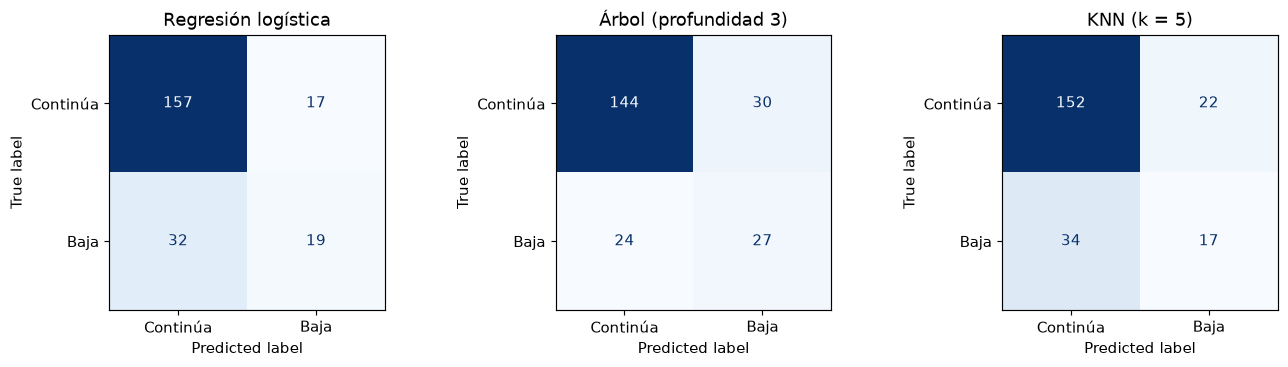

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
filas = []
for ax, (nombre, m) in zip(axes, modelos.items()):
    pred = m.predict(Xc_pru)
    vn, fp, fn, vp = confusion_matrix(yc_pru, pred).ravel()
    filas.append({
        "Modelo": nombre, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "Exactitud": accuracy_score(yc_pru, pred),
        "Precisión": precision_score(yc_pru, pred),
        "Recall": recall_score(yc_pru, pred),
        "F1": f1_score(yc_pru, pred),
    })
    ConfusionMatrixDisplay.from_estimator(
        m, Xc_pru, yc_pru, display_labels=["Continúa", "Baja"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

tabla_clf = pd.DataFrame(filas).set_index("Modelo").round(3)
print(tabla_clf.to_string())
print(f"\nComprobación manual (Regresión logística): Precisión = 19/36 = {19/36:.3f} | Recall = 19/51 = {19/51:.3f}")

## 5. Costo de errores, ajuste de umbral y modelo final (G-12)

In [ ]:
prob = modelos["Regresión logística"].predict_proba(Xc_pru)[:, 1]
for umbral in (0.5, 0.4, 0.3, 0.2):
    pred = (prob >= umbral).astype(int)
    print(
        f"Umbral {umbral:.1f}: precisión = {precision_score(yc_pru, pred):.2f}  "
        f"recall = {recall_score(yc_pru, pred):.2f}  F1 = {f1_score(yc_pru, pred):.2f}  "
        f"clientes a llamar = {pred.sum()}"
    )

Umbral 0.5: precisión = 0.53  recall = 0.37  F1 = 0.44  clientes a llamar = 36
Umbral 0.4: precisión = 0.56  recall = 0.53  F1 = 0.55  clientes a llamar = 48
Umbral 0.3: precisión = 0.46  recall = 0.61  F1 = 0.53  clientes a llamar = 67
Umbral 0.2: precisión = 0.40  recall = 0.75  F1 = 0.52  clientes a llamar = 94


- **Costo de errores:** FP = llamada innecesaria y posible descuento (costo bajo); FN = perder al cliente y sus ingresos mensuales futuros (costo alto).
- **Métrica principal:** **Recall** (Tabla 17), porque el falso negativo es el error más costoso.
- **Modelo elegido:** **Regresión logística con umbral `0.3`**. Alcanza **recall = 0.61** (detecta 31 de 51 bajas reales, frente a 19 con umbral `0.5` y 27 del árbol), con **67 llamadas** viables para un proveedor regional (bajar a `0.2` exigiría 94 llamadas).

## 6. Resumen comparativo final (LC2)

| Problema | Modelo | Métrica principal | Referencia | Decisión |
| :--- | :--- | :--- | :--- | :--- |
| Regresión (alquileres) | Simple (área) | $R^2 = 0.707$, RMSE = S/ 119 | CV $R^2 = 0.655 \pm 0.058$ | Base |
| Regresión (alquileres) | **Múltiple (8 variables)** | **$R^2 = 0.838$, RMSE = S/ 88** | CV $R^2 = 0.833 \pm 0.044$ | **Elegido** |
| Clasificación (ISP) | Regresión logística ($u = 0.5$) | Recall = 0.373 | Prec. 0.528, F1 0.437, 36 llamadas | Descartado |
| Clasificación (ISP) | Árbol (profundidad 3) | Recall = 0.529 | Prec. 0.474, F1 0.500, 57 llamadas | Descartado |
| Clasificación (ISP) | KNN ($k = 5$) | Recall = 0.333 | Prec. 0.436, F1 0.378, 39 llamadas | Descartado |
| Clasificación (ISP) | **Regresión logística ($u = 0.3$)** | **Recall = 0.608** | Prec. 0.463, F1 0.525, **67 llamadas** | **Elegido** |